<center><h1>bagai_sanchit_HW6</h1></center>

Name: Sanchit Bagai
<br>
Github Username: baked-potatoes
<br>
USC ID: 1033382623

## 1. Tree-Based Methods

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import cross_val_score


np.random.seed(42)

### (a) Download the APS Failure data

In [2]:
def load_aps(path):
    with open(path) as f:
        lines = f.readlines()
    skip = next(i for i, l in enumerate(lines) if l.startswith("class"))
    return pd.read_csv(path, skiprows=skip, na_values="na")

train = load_aps("../data/aps_failure_training_set.csv")
test  = load_aps("../data/aps_failure_test_set.csv")

train["class"] = (train["class"] == "pos").astype(int)
test["class"]  = (test["class"] == "pos").astype(int)

X_train, y_train = train.drop(columns="class"), train["class"]
X_test,  y_test  = test.drop(columns="class"),  test["class"]

print(train.shape, test.shape)
print("Missing fraction (train):", X_train.isna().mean().mean())

(60000, 171) (16000, 171)
Missing fraction (train): 0.08333480392156863


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

In [3]:
miss = X_train.isna().mean().sort_values(ascending=False)
print(miss.head(10))

X_train_imp = pd.DataFrame(
    SimpleImputer(strategy="median").fit_transform(X_train), columns=X_train.columns)
X_test_imp = pd.DataFrame(
    SimpleImputer(strategy="median").fit_transform(X_test), columns=X_test.columns)

print(X_train_imp.isna().sum().sum(), X_test_imp.isna().sum().sum())

br_000    0.821067
bq_000    0.812033
bp_000    0.795667
bo_000    0.772217
ab_000    0.772150
cr_000    0.772150
bn_000    0.733483
bm_000    0.659150
bl_000    0.454617
bk_000    0.383900
dtype: float64
0 0


Common techniques are: deletion, mean/median imputation, constant/indicator imputation, kNN imputation and iterative (MICE) imputation. I imputed the data using median as it's fast and robust to heavy right skew in this data (the test set is imputed with its own median).

#### (ii) Calculate the coefficient of variation

In [4]:
cv = (X_train_imp.std() / X_train_imp.mean()).abs()
cv = cv.replace([np.inf, -np.inf], np.nan).dropna().sort_values(ascending=False)
print(cv.head(15))

cf_000    244.887517
co_000    244.507385
ad_000    244.322816
cs_009    237.930554
dh_000    123.216097
dj_000    117.494225
ag_000     92.917755
as_000     87.332500
ay_009     84.733735
ak_000     80.424975
az_009     77.838544
ch_000     77.453857
au_000     68.882751
cr_000     58.078072
ay_001     52.824714
dtype: float64


In [5]:
for c in ["cf_000", "co_000", "ad_000", "cs_009"]:
    print(c, "max row:", X_train_imp[c].idxmax(), "max:", X_train_imp[c].max(), "median:", X_train_imp[c].median())

cf_000 max row: 45977 max: 8584297736.0 median: 2.0
co_000 max row: 45977 max: 8584297742.0 median: 8.0
ad_000 max row: 45977 max: 8584297742.0 median: 126.0
cs_009 max row: 5679 max: 44902992.0 median: 0.0


The highest coeff of variation are dominated by single extreme rows. The ranking reflects outliers more than meaningful variation.

#### (iii) Plot a correlation matrix

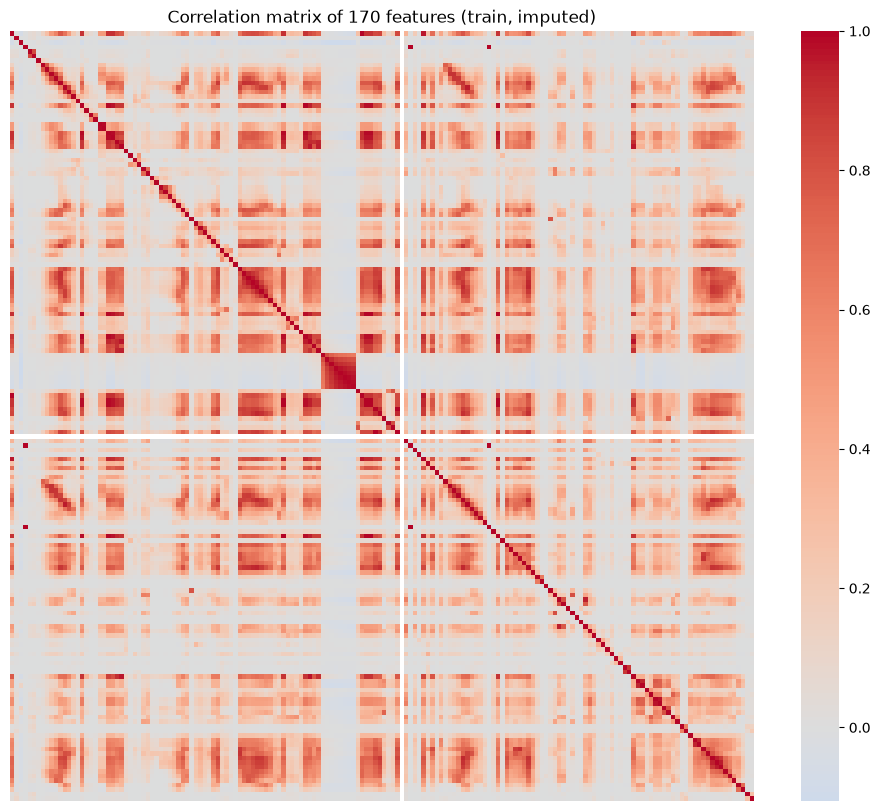

bv_000  cq_000    1.000000
bu_000  cq_000    1.000000
        bv_000    1.000000
cf_000  co_000    1.000000
ad_000  cf_000    1.000000
        co_000    1.000000
aa_000  bt_000    0.998774
ah_000  bg_000    0.997745
bb_000  bv_000    0.996258
        bu_000    0.996258
dtype: float64


In [6]:
corr = X_train_imp.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, xticklabels=False, yticklabels=False)
plt.title("Correlation matrix of 170 features (train, imputed)")
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print(upper.abs().sort_values(ascending=False).head(10))

Many features are highly correlated (some almost perfectly), so the data has a lot of redundancy.

#### (iv) Make scatter plots and box plots

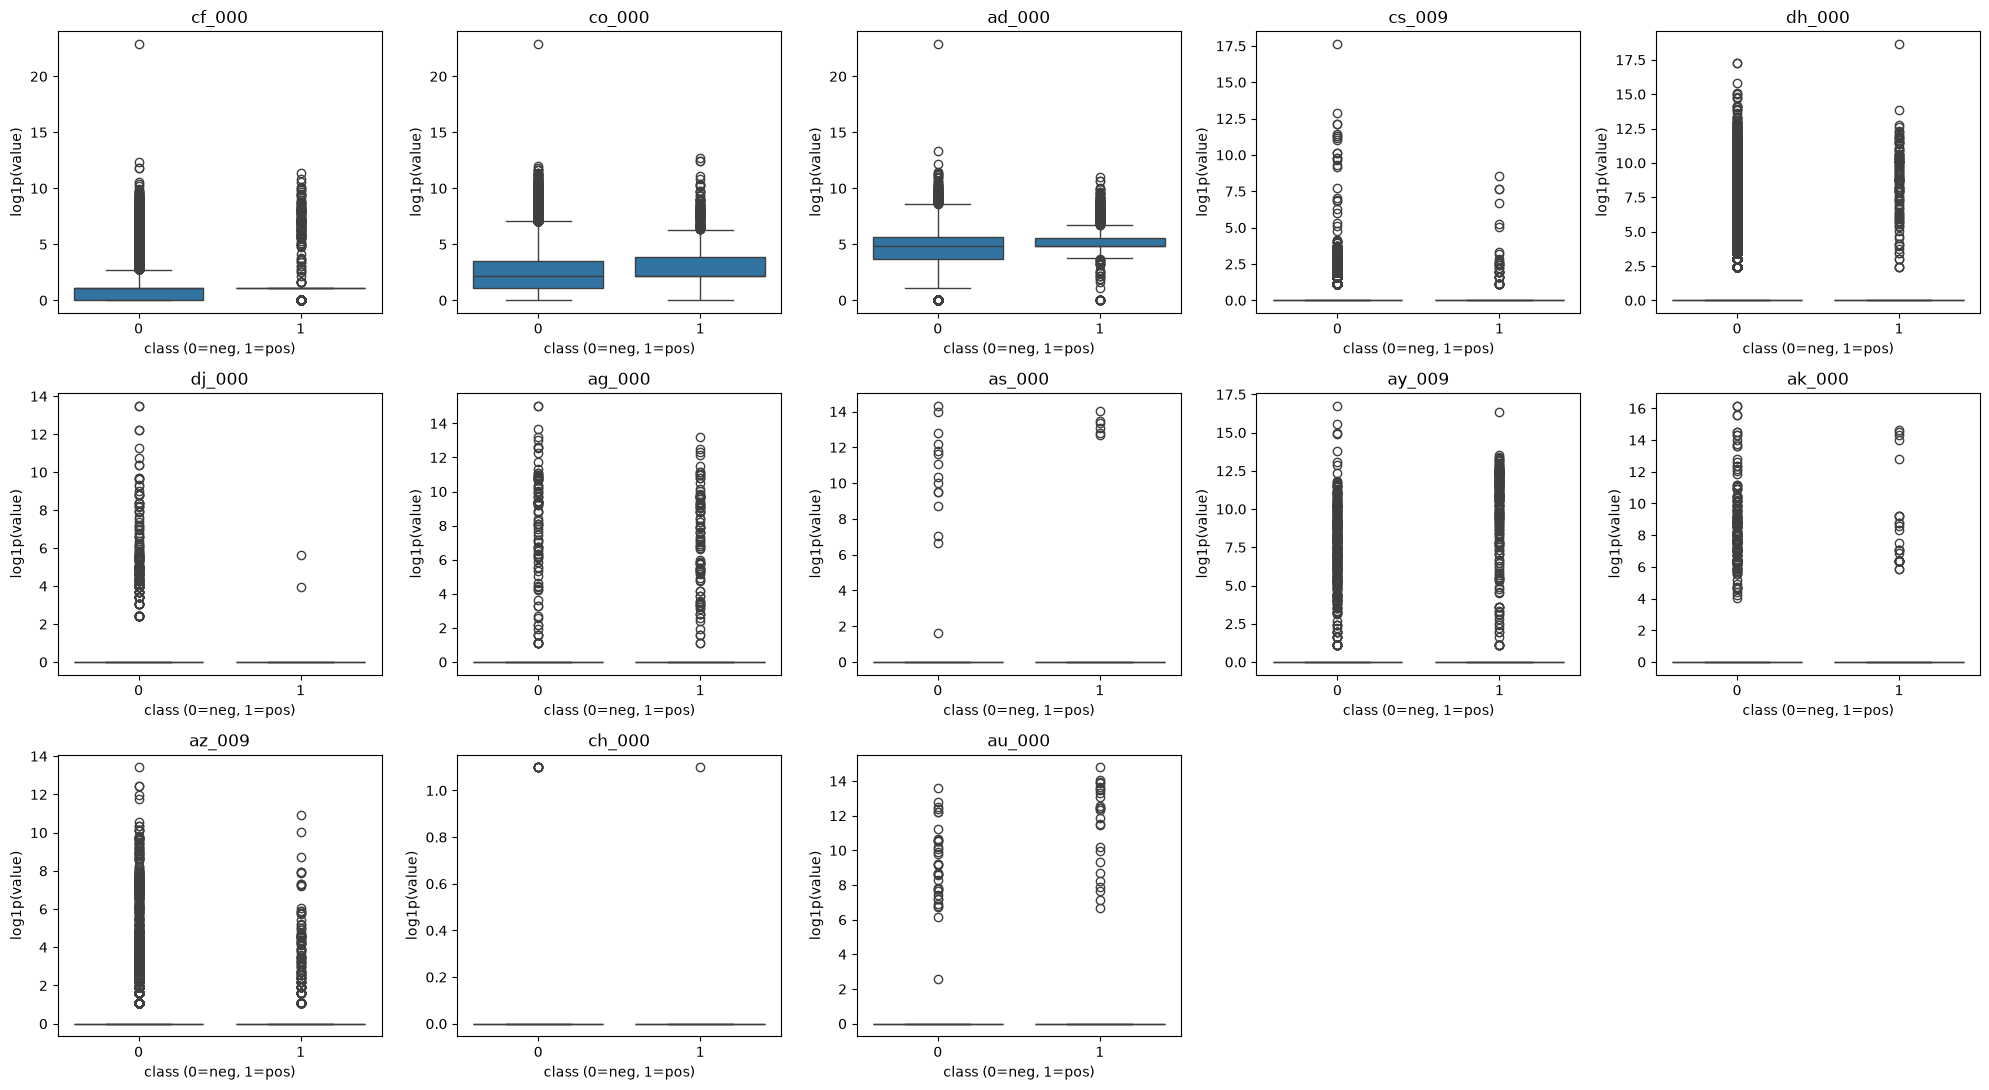

In [7]:
top13 = cv.head(13).index.tolist()

fig, axes = plt.subplots(3, 5, figsize=(20, 11))
for ax, f in zip(axes.ravel(), top13):
    sns.boxplot(x=y_train, y=np.log1p(X_train_imp[f]), ax=ax)
    ax.set_title(f)
    ax.set_xlabel("class (0=neg, 1=pos)")
    ax.set_ylabel("log1p(value)")
for ax in axes.ravel()[len(top13):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

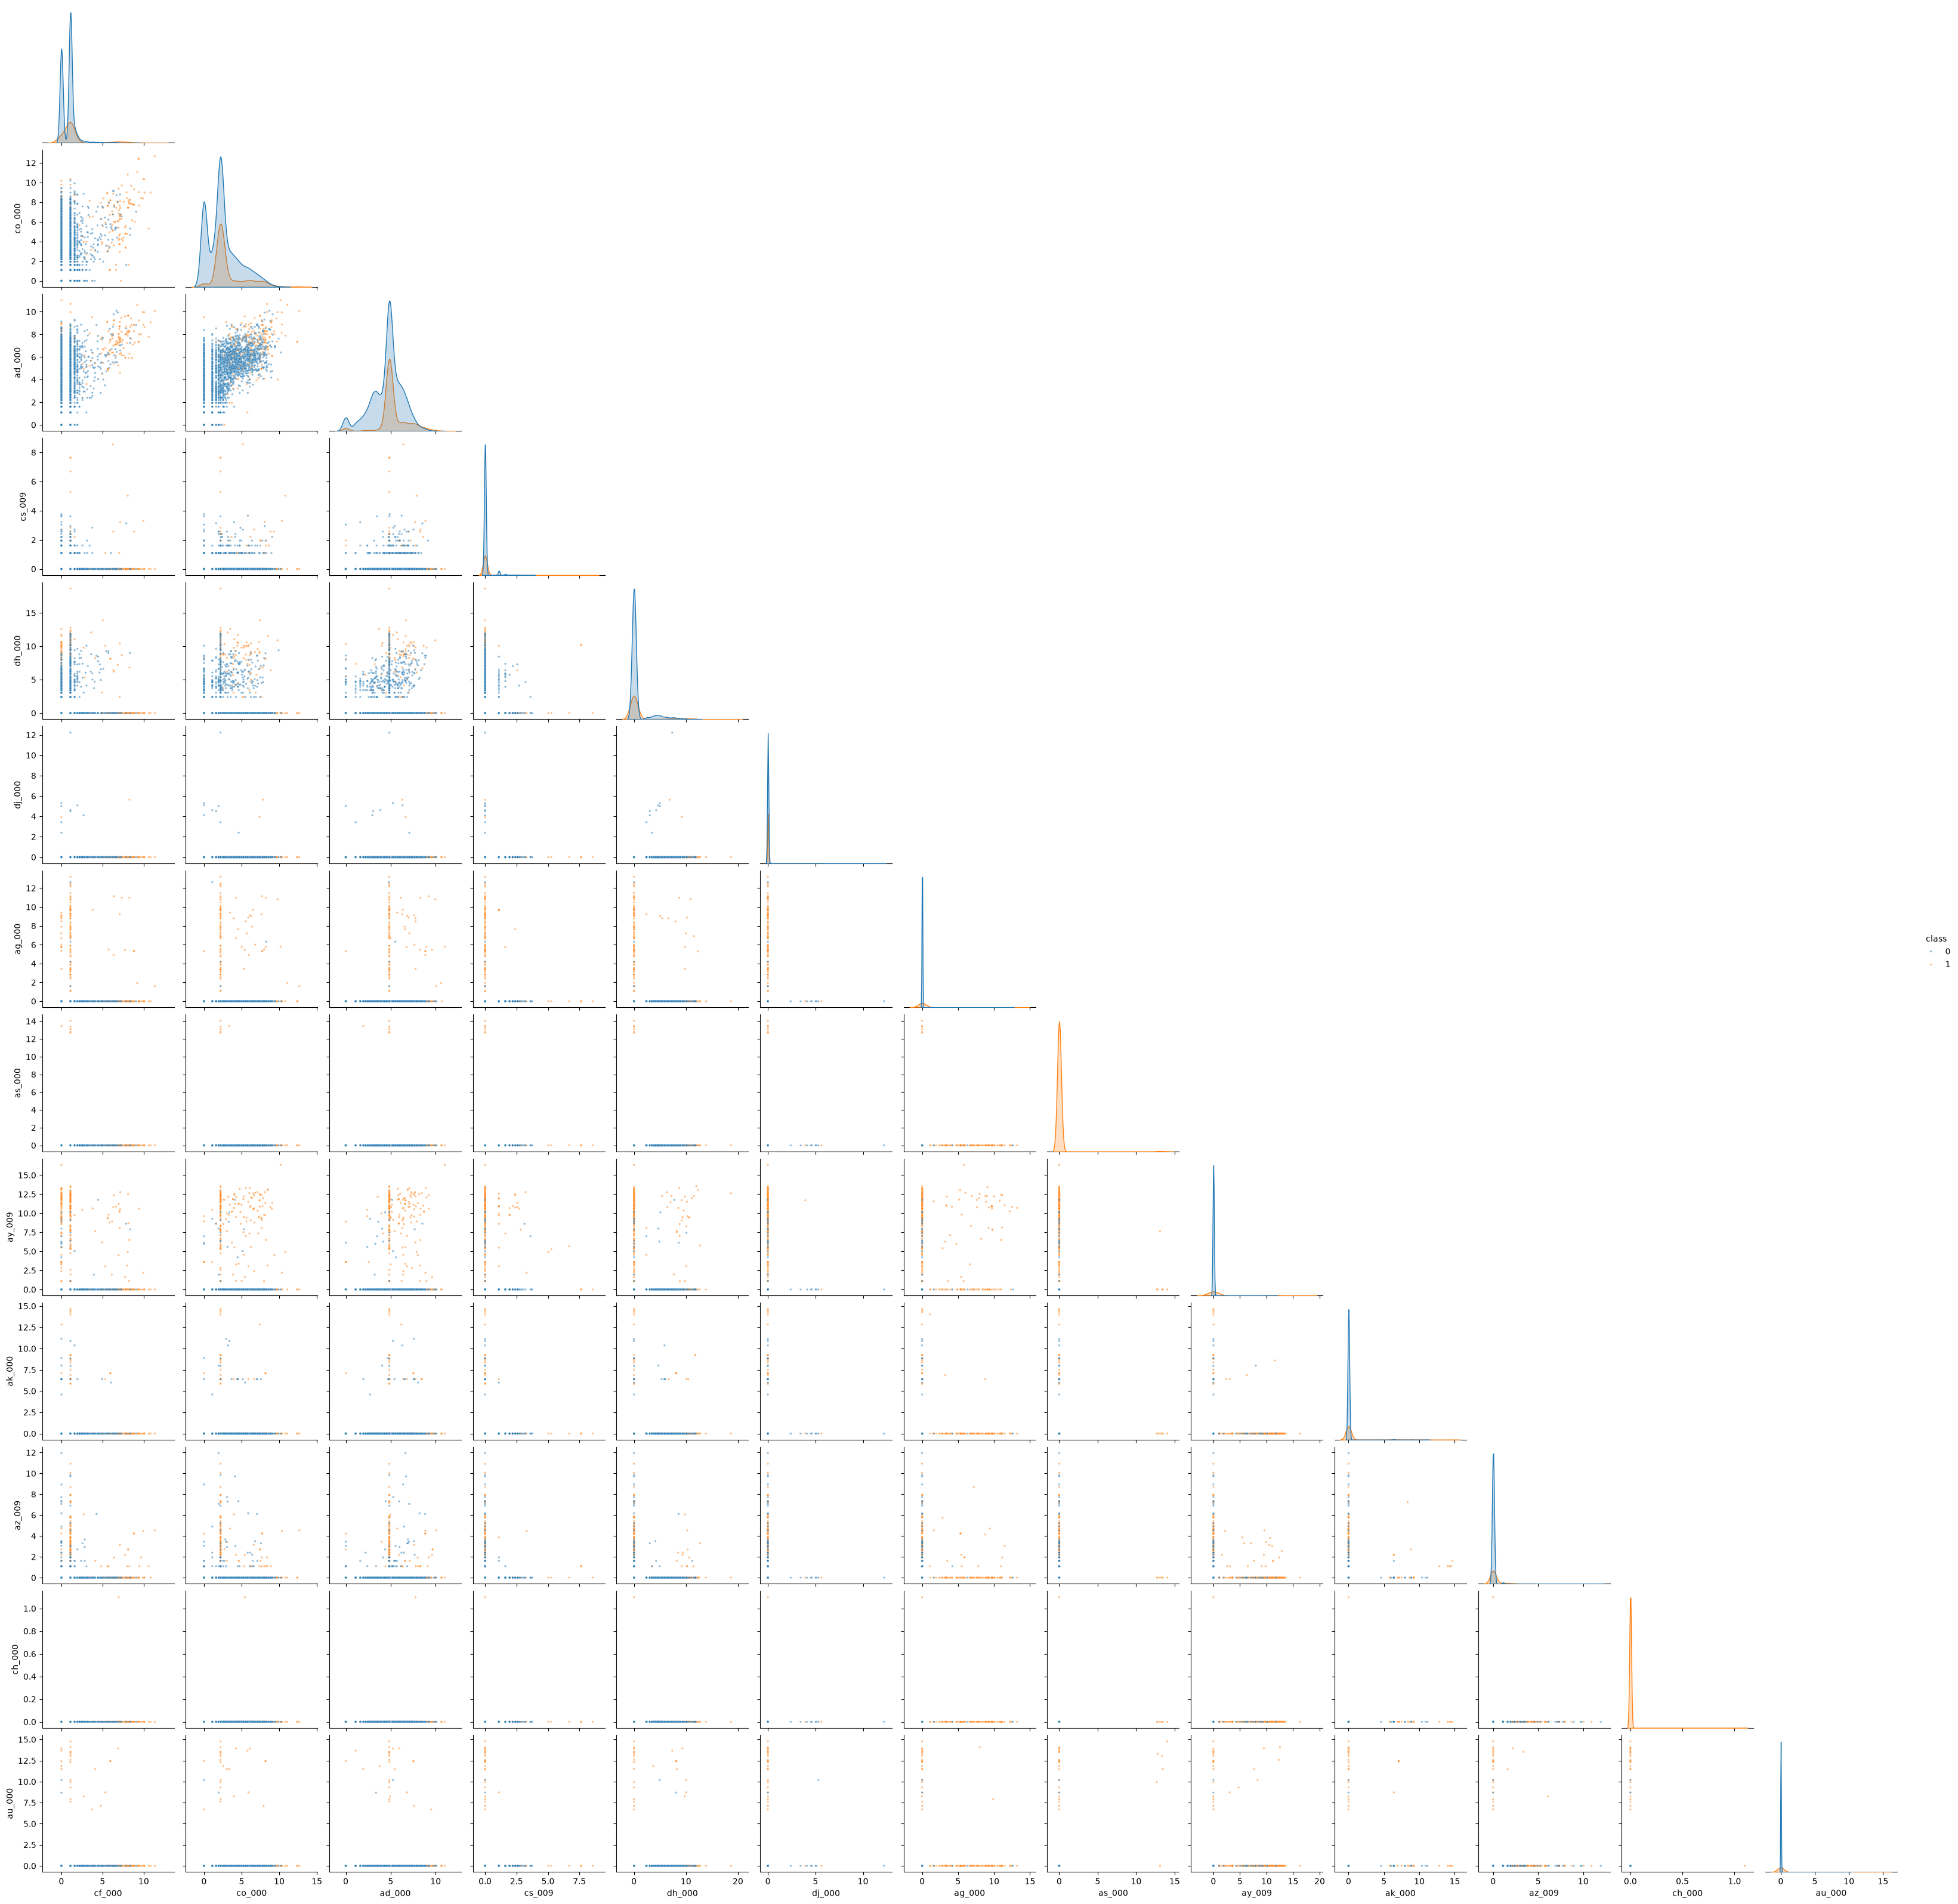

In [8]:
pos = X_train_imp[y_train == 1]
neg = X_train_imp[y_train == 0].sample(3000, random_state=42)
plot_df = np.log1p(pd.concat([pos, neg])[top13])
plot_df["class"] = [1] * len(pos) + [0] * len(neg)

sns.pairplot(plot_df, hue="class", corner=True, plot_kws={"s": 6, "alpha": 0.5})
plt.show()

No, the classes overlap heavily for nearly all plotted features, so significance can't be concluded.

#### (v) Is this data set imbalanced?

In [9]:
print(y_train.value_counts())
print(y_test.value_counts())
print("neg:pos ratio (train):", (y_train == 0).sum() / (y_train == 1).sum())
print("positive fraction (train):", y_train.mean())

class
0    59000
1     1000
Name: count, dtype: int64
class
0    15625
1      375
Name: count, dtype: int64
neg:pos ratio (train): 59.0
positive fraction (train): 0.016666666666666666


The dataset has 59000 negative and 1000 positive samples (59:1), so it's strongly imbalanced.

### (c) Train a random forest

--- RF train ---
Confusion matrix [[TN FP],[FN TP]]:
 [[59000     0]
 [    0  1000]]
AUC: 1.0000   misclassification: 0.0000
--- RF test ---
Confusion matrix [[TN FP],[FN TP]]:
 [[15609    16]
 [  100   275]]
AUC: 0.9944   misclassification: 0.0072

OOB error: 0.0059


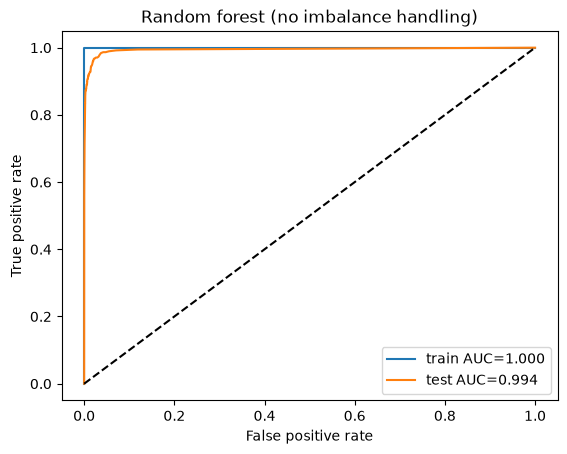

In [10]:
def evaluate(name, model, X, y):
    prob = model.predict_proba(X)[:, 1]
    pred = (prob >= 0.5).astype(int)
    cm = confusion_matrix(y, pred)
    auc = roc_auc_score(y, prob)
    err = 1 - accuracy_score(y, pred)
    print(f"--- {name} ---")
    print("Confusion matrix [[TN FP],[FN TP]]:\n", cm)
    print(f"AUC: {auc:.4f}   misclassification: {err:.4f}")
    fpr, tpr, _ = roc_curve(y, prob)
    return fpr, tpr, auc

rf = RandomForestClassifier(n_estimators=200, oob_score=True,
                            n_jobs=-1, random_state=42)
rf.fit(X_train_imp, y_train)

fpr_tr, tpr_tr, auc_tr = evaluate("RF train", rf, X_train_imp, y_train)
fpr_te, tpr_te, auc_te = evaluate("RF test",  rf, X_test_imp,  y_test)

print(f"\nOOB error: {1 - rf.oob_score_:.4f}")

plt.plot(fpr_tr, tpr_tr, label=f"train AUC={auc_tr:.3f}")
plt.plot(fpr_te, tpr_te, label=f"test AUC={auc_te:.3f}")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("Random forest (no imbalance handling)"); plt.legend(); plt.show()

Test misclassification is 0.0072 with AUC 0.9944 and the OOB error of 0.0059 is close to test error but 100 of 375 test failures are missed.

### (d) Research class imbalance in random forest

--- RF balanced train ---
Confusion matrix [[TN FP],[FN TP]]:
 [[59000     0]
 [    0  1000]]
AUC: 1.0000   misclassification: 0.0000
--- RF balanced test ---
Confusion matrix [[TN FP],[FN TP]]:
 [[15611    14]
 [  159   216]]
AUC: 0.9919   misclassification: 0.0108

OOB error (balanced): 0.0077


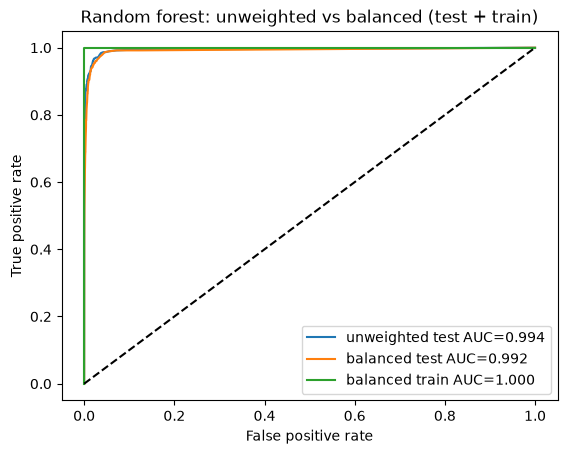

In [11]:
rf_bal = RandomForestClassifier(n_estimators=200, oob_score=True,
                                class_weight="balanced_subsample",
                                n_jobs=-1, random_state=42)
rf_bal.fit(X_train_imp, y_train)

fpr_tr2, tpr_tr2, auc_tr2 = evaluate("RF balanced train", rf_bal, X_train_imp, y_train)
fpr_te2, tpr_te2, auc_te2 = evaluate("RF balanced test",  rf_bal, X_test_imp,  y_test)
print(f"\nOOB error (balanced): {1 - rf_bal.oob_score_:.4f}")

plt.plot(fpr_te,  tpr_te,  label=f"unweighted test AUC={auc_te:.3f}")
plt.plot(fpr_te2, tpr_te2, label=f"balanced test AUC={auc_te2:.3f}")
plt.plot(fpr_tr2, tpr_tr2, label=f"balanced train AUC={auc_tr2:.3f}")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("Random forest: unweighted vs balanced (test + train)"); plt.legend()
plt.show()

With `balanced_subsample` (RF can also use `balanced bootstrap sampling` or `threshold moving`) weights, results got worse (test misclassification is 0.0108, AUC is 0.9919 and 159 missed failures), so class weighting did not help here.

### (e) XGBoost and Model Trees

Fitting 5 folds for each of 5 candidates, totalling 25 fits
CV AUC by alpha:
  alpha=0      AUC=0.9876
  alpha=0.1    AUC=0.9885
  alpha=1      AUC=0.9894
  alpha=10     AUC=0.9896
  alpha=100    AUC=0.9822
Best alpha: 10
5-fold CV misclassification: 0.0072
--- XGB train ---
Confusion matrix [[TN FP],[FN TP]]:
 [[58960    40]
 [  160   840]]
AUC: 0.9971   misclassification: 0.0033
--- XGB test ---
Confusion matrix [[TN FP],[FN TP]]:
 [[15599    26]
 [  104   271]]
AUC: 0.9961   misclassification: 0.0081


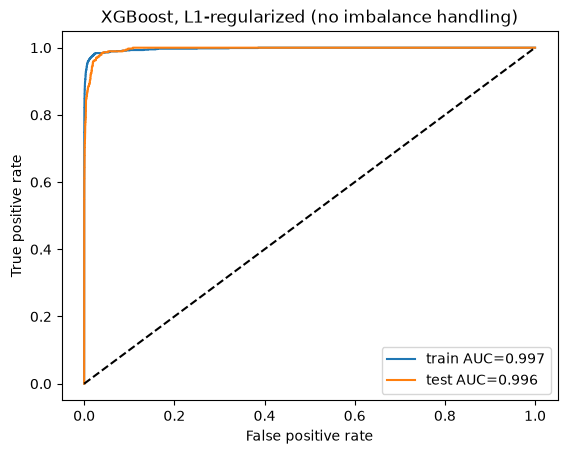

In [12]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

xgb = XGBClassifier(objective="binary:logistic", n_estimators=200,
                    learning_rate=0.1, max_depth=4, tree_method="hist",
                    n_jobs=-1, random_state=42, eval_metric="logloss")

param_grid = {"reg_alpha": [0, 0.1, 1, 10, 100]}

gs = GridSearchCV(xgb, param_grid, scoring="roc_auc", cv=skf, n_jobs=1, verbose=1)
gs.fit(X_train_imp, y_train)

print("CV AUC by alpha:")
for a, s in zip(param_grid["reg_alpha"], gs.cv_results_["mean_test_score"]):
    print(f"  alpha={a:<6} AUC={s:.4f}")
print("Best alpha:", gs.best_params_["reg_alpha"])


best = gs.best_estimator_
cv_acc = cross_val_score(best, X_train_imp, y_train, cv=skf, scoring="accuracy")
print(f"5-fold CV misclassification: {1 - cv_acc.mean():.4f}")

fpr_trx, tpr_trx, auc_trx = evaluate("XGB train", best, X_train_imp, y_train)
fpr_tex, tpr_tex, auc_tex = evaluate("XGB test",  best, X_test_imp,  y_test)

plt.plot(fpr_trx, tpr_trx, label=f"train AUC={auc_trx:.3f}")
plt.plot(fpr_tex, tpr_tex, label=f"test AUC={auc_tex:.3f}")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("XGBoost, L1-regularized (no imbalance handling)"); plt.legend(); plt.show()

The best $\alpha$ was 10 by 5-fold CV, the CV error of 0.0072 is close to the test error of 0.0081 and AUC of 0.9961 and 104 test failures still missed.

### (f) Use SMOTE to pre-process your data

Before SMOTE: {0: 59000, 1: 1000}
After SMOTE:  {0: 59000, 1: 59000}
Fitting 5 folds for each of 5 candidates, totalling 25 fits
CV AUC by alpha (SMOTE inside each fold):
  alpha=0      AUC=0.9861
  alpha=0.1    AUC=0.9859
  alpha=1      AUC=0.9851
  alpha=10     AUC=0.9858
  alpha=100    AUC=0.9842
Best alpha: 0
5-fold CV misclassification (SMOTE): 0.0091
--- XGB+SMOTE train ---
Confusion matrix [[TN FP],[FN TP]]:
 [[58784   216]
 [   52   948]]
AUC: 0.9989   misclassification: 0.0045
--- XGB+SMOTE test ---
Confusion matrix [[TN FP],[FN TP]]:
 [[15465   160]
 [   45   330]]
AUC: 0.9932   misclassification: 0.0128


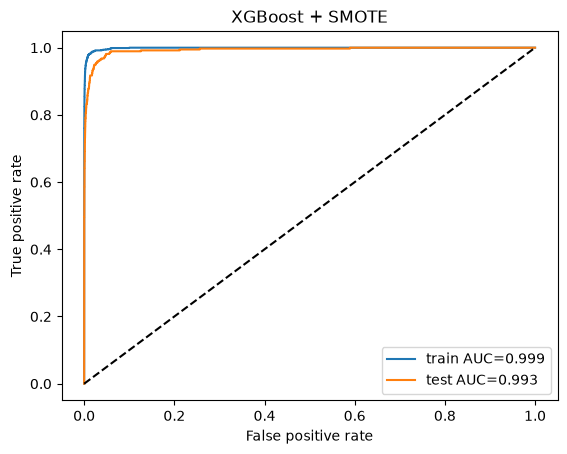

In [13]:
X_sm, y_sm = SMOTE(random_state=42).fit_resample(X_train_imp, y_train)
print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE: ", pd.Series(y_sm).value_counts().to_dict())

pipe = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("xgb", XGBClassifier(objective="binary:logistic", n_estimators=200,
                          learning_rate=0.1, max_depth=4, tree_method="hist",
                          n_jobs=-1, random_state=42, eval_metric="logloss")),
])

param_grid_s = {"xgb__reg_alpha": [0, 0.1, 1, 10, 100]}

gs_s = GridSearchCV(pipe, param_grid_s, scoring="roc_auc", cv=skf, n_jobs=1, verbose=1)
gs_s.fit(X_train_imp, y_train)

print("CV AUC by alpha (SMOTE inside each fold):")
for a, s in zip(param_grid_s["xgb__reg_alpha"], gs_s.cv_results_["mean_test_score"]):
    print(f"  alpha={a:<6} AUC={s:.4f}")
print("Best alpha:", gs_s.best_params_["xgb__reg_alpha"])

best_s = gs_s.best_estimator_
cv_acc_s = cross_val_score(best_s, X_train_imp, y_train, cv=skf, scoring="accuracy")
print(f"5-fold CV misclassification (SMOTE): {1 - cv_acc_s.mean():.4f}")

fpr_trs, tpr_trs, auc_trs = evaluate("XGB+SMOTE train", best_s, X_train_imp, y_train)
fpr_tes, tpr_tes, auc_tes = evaluate("XGB+SMOTE test",  best_s, X_test_imp,  y_test)

plt.plot(fpr_trs, tpr_trs, label=f"train AUC={auc_trs:.3f}")
plt.plot(fpr_tes, tpr_tes, label=f"test AUC={auc_tes:.3f}")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("XGBoost + SMOTE"); plt.legend(); plt.show()

Applying SMOTE in each CV fold (in training part) reduced the test false negatives from 104 to 45 but raised the number of false positives to 160 from 26 (compared to uncompensated XGBoost in 1e). The test error rose from 0.0081 to 0.0128 and AUC fell from 0.9961 to 0.9932.

## 2. ISLR 6.6.3

a) iv) Steadily decreases. A larger s allows more coeff values, so the training RSS can only fall until it reaches the least squares fit.

b) ii) Decrease initially, then increase in U shape. A small s underfits and a large s overfits the training data.

c) iii) Steadily increases. A larger s makes the fit depend more on the particular training sample.

d) iv) Steadily decreases. A more flexible model fits the true relationship better.

e) v) Remains constant. The irreducible error is the noise variance which isn't dependent on model or s.

## 3. ISLR 6.6.5

a) $\min_{\beta_1,\beta_2} \; (y_1 - \beta_1 x_{11} - \beta_2 x_{12})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{22})^2 + \lambda(\beta_1^2 + \beta_2^2)$

b) Since $x_{11} = x_{12}$ and $x_{21} = x_{22}$, the RSS depends on $S = \beta_1 + \beta_2$. For a fixed S, the penalty $\beta_1^2 + \beta_2^2 = (S^2 + (\beta_1 - \beta_2)^2) / 2$ is smallest when $\beta_1 = \beta_2$ and the strictly convex ridge objective has a single minimizer $\hat{\beta}_1 = \hat{\beta}_2$.

c) $\min_{\beta_1,\beta_2} \; (y_1 - \beta_1 x_{11} - \beta_2 x_{12})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{22})^2 + \lambda(|\beta_1| + |\beta_2|)$

d) The RSS here depends on $S = \beta_1 + \beta_2$. The penalty $|\beta_1| + |\beta_2|$ equals $|S|$ whenever both $\beta$ have the same sign (or one is zero) and is larger otherwise. The optimal sum $S^*$ is fixed and every pair with $\beta_1 + \beta_2 = S^*$ and $\beta_1$, $\beta_2$ of the same sign is a solution: if $S^* > 0$ they are $(t, S^* - t)$ for any t in $[0, S^*]$ and if $S^* < 0$, the same with t in $[S^*, 0]$ giving infinite solutions along the line segment.

## 4. ISLR 8.4.5

Majority vote: RED. 6 of the 10 estimates predict RED, so majority vote picks red.

Average probability: GREEN. The 10 estimates average to 0.45, so average vote picks green.

The two approaches have different answers because the green leaning trees are more confident, pulling the average down despite red being most voted.

## 5. ISLR 9.7.3

(The corresponding plots are under the md cell)

a) Plot is present below

b) The hyperplane plotted (solid line) is: $0.5 - X_1 + X_2 = 0$

c) Classify red if $0.5 - X_1 + X_2 > 0$ and blue otherwise. Here, $\beta_0 = 0.5; \beta_1 = -1; \beta_2 = 1$

d) The dotted line in the plot.

e) Green circles in the plot. Support vectors: $(2, 2), (4, 4)$ in red and $(2, 1), (4, 3)$ in blue.

f) It won't affect the hyperplane as it's not a support vector and well outside the margin.

g) Left panel on the second figure. $0.2 - X_1 + X_2 = 0$

h) Right panel on the second figure. Added an entry with label red at $(4, 2)$

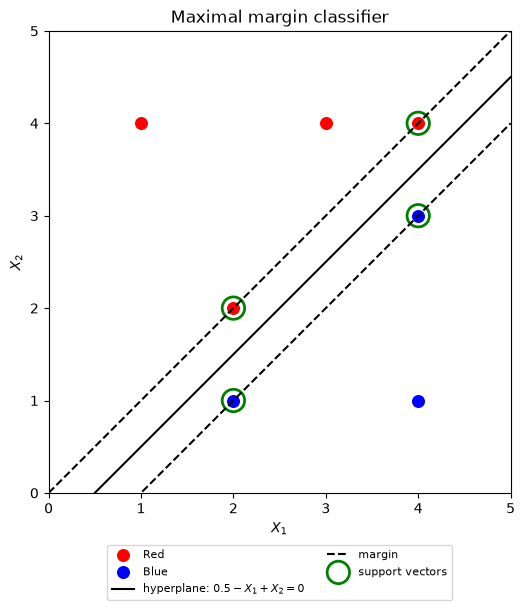

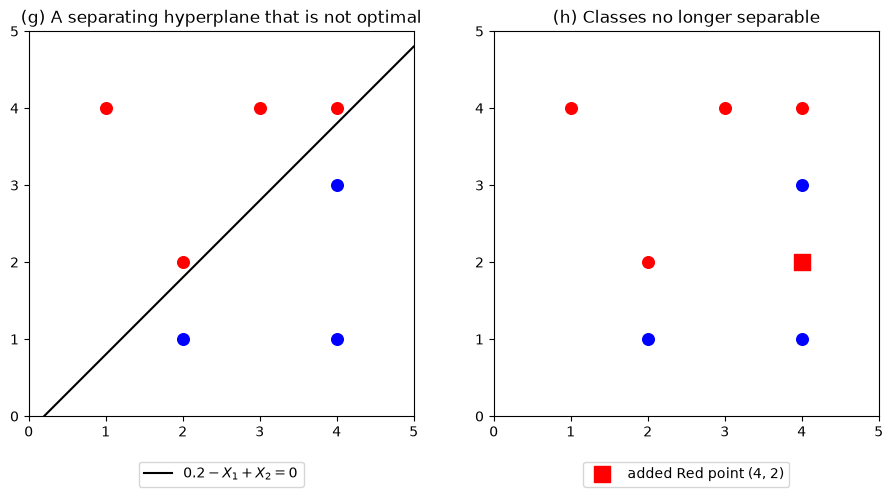

In [14]:
import numpy as np
import matplotlib.pyplot as plt

red  = np.array([[3,4],[2,2],[4,4],[1,4]])
blue = np.array([[2,1],[4,3],[4,1]])
x = np.linspace(0, 5, 100)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(*red.T,  c="red",  s=70, label="Red")
ax.scatter(*blue.T, c="blue", s=70, label="Blue")
ax.plot(x, x - 0.5, "k-",  label=r"hyperplane: $0.5 - X_1 + X_2 = 0$")
ax.plot(x, x,       "k--", label="margin")
ax.plot(x, x - 1,   "k--")
sv = np.array([[2,2],[4,4],[2,1],[4,3]])
ax.scatter(*sv.T, s=260, facecolors="none", edgecolors="green", linewidths=2, label="support vectors")
ax.set_xlim(0, 5); ax.set_ylim(0, 5); ax.set_aspect("equal")
ax.set_xlabel("$X_1$"); ax.set_ylabel("$X_2$")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), fontsize=8, ncol=2)
ax.set_title("Maximal margin classifier")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
ax = axes[0]
ax.scatter(*red.T, c="red", s=70); ax.scatter(*blue.T, c="blue", s=70)
ax.plot(x, x - 0.2, "k-", label=r"$0.2 - X_1 + X_2 = 0$")
ax.set_xlim(0, 5); ax.set_ylim(0, 5); ax.set_aspect("equal")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1))
ax.set_title("(g) A separating hyperplane that is not optimal")
ax = axes[1]
ax.scatter(*red.T, c="red", s=70); ax.scatter(*blue.T, c="blue", s=70)
ax.scatter([4], [2], c="red", s=120, marker="s", label="added Red point (4, 2)")
ax.set_xlim(0, 5); ax.set_ylim(0, 5); ax.set_aspect("equal")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1))
ax.set_title("(h) Classes no longer separable")
plt.show()